# 04 · K-prototypes y distancia al centro del cluster

**K-prototypes** (Huang, 1998) es como K-means pero acepta variables numéricas **y** categóricas a la vez:

* cada cluster tiene un **prototipo** (su "contrato típico"): la **media** en las variables numéricas y la **moda** en las categóricas;
* cada contrato se asigna al prototipo más cercano según la distancia del notebook 02.

**Problema:** K-prototypes solo **agrupa**; todos los contratos quedan en algún cluster y ninguno sale marcado como atípico. Para detectar anomalías:

1. calculamos la **distancia de cada contrato al prototipo de su cluster**;
2. marcamos como atípicos los contratos **demasiado lejos** del prototipo, comparándolos con los demás contratos **de su mismo cluster**.

In [ ]:
from pathlib import Path

RAIZ = Path("..")
DATA = RAIZ / "data"
MUESTRAS = DATA / "muestras"
RESULTADOS = RAIZ / "resultados"
MODELOS = RESULTADOS / "modelos"
FIGURAS = RESULTADOS / "figuras"
TABLAS = RESULTADOS / "tablas"
for carpeta in [MUESTRAS, MODELOS, FIGURAS, TABLAS]:
    carpeta.mkdir(parents=True, exist_ok=True)

NUMERICAS = [
    "log_valor_contrato",          # log(1 + valor del contrato)
    "log_ratio_contrato_proceso",  # log(valor del contrato / valor estimado del proceso)
    "ratio_adiciones",             # valor adicionado / valor del contrato
    "log_plazo_dias",              # log(1 + plazo en días)
    "log_adiciones_dias",          # log(1 + días adicionados)
    "slog_dias_firma_cargue",      # log "con signo" de los días entre la firma y la publicación
]
CATEGORICAS = [
    "modalidad_de_contratacion",
    "tipo_de_contrato",
    "orden_entidad",
    "nombre_grupo",
    "tipo_identifi_del_contratista",
    "destino_gasto",
    "estado_del_proceso",
]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from kmodes.kprototypes import KPrototypes
from sklearn.metrics import silhouette_score

GAMMA = 0.5
N_NUM = len(NUMERICAS)
prep = {"cruda": joblib.load(MODELOS / "preparacion_cruda.joblib"),
        "limpia": joblib.load(MODELOS / "preparacion_limpia.joblib")}


def entrenar_kprototypes(X_num, X_cat, k, n_init):
    X = np.hstack([X_num, X_cat])
    modelo = KPrototypes(n_clusters=k, gamma=GAMMA, init="Cao", n_init=n_init,
                         max_iter=50, random_state=42, n_jobs=-1)
    modelo.fit(X, categorical=list(range(N_NUM, X.shape[1])))
    return modelo

## 1. Elegir el número de clusters k

Probamos k = 2 … 8 con una submuestra de 10.000 contratos (K-prototypes es lento) y miramos dos medidas:

* **Costo** (suma de distancias al prototipo): siempre baja al aumentar k; se busca un "codo".
* **Silueta** (entre -1 y 1): qué tan bien separado está cada punto de los otros clusters. **Más alto es mejor.**

Elegimos el k con **mayor silueta**. Usamos la matriz `Z` del notebook 02, cuya distancia es la misma de K-prototypes.

In [2]:
rng = np.random.default_rng(42)
evaluacion = []
for escenario in ["cruda", "limpia"]:
    p = prep[escenario]
    sub = rng.choice(len(p["X_num"]), 10_000, replace=False)
    sub_silueta = sub[:5_000]
    for k in range(2, 9):
        modelo = entrenar_kprototypes(p["X_num"][sub], p["X_cat"][sub], k, n_init=2)
        etiquetas = modelo.labels_[:5_000]
        silueta = silhouette_score(p["Z"][sub_silueta], etiquetas)
        evaluacion.append({"escenario": escenario, "k": k, "costo": modelo.cost_, "silueta": silueta})
        print(f"{escenario:6s} k={k}  costo={modelo.cost_:10,.0f}  silueta={silueta:.3f}")

evaluacion = pd.DataFrame(evaluacion)
evaluacion.to_csv(TABLAS / "kprototypes_eleccion_k.csv", index=False)

cruda  k=2  costo=    43,565  silueta=0.563


cruda  k=3  costo=    36,725  silueta=0.248


cruda  k=4  costo=    30,556  silueta=0.274


cruda  k=5  costo=    21,852  silueta=0.326


cruda  k=6  costo=    20,485  silueta=0.273


cruda  k=7  costo=    19,560  silueta=0.241


... (4 outputs left out)

limpia k=5  costo=    36,947  silueta=0.162


limpia k=6  costo=    35,089  silueta=0.151


limpia k=7  costo=    33,685  silueta=0.154


limpia k=8  costo=    32,839  silueta=0.148


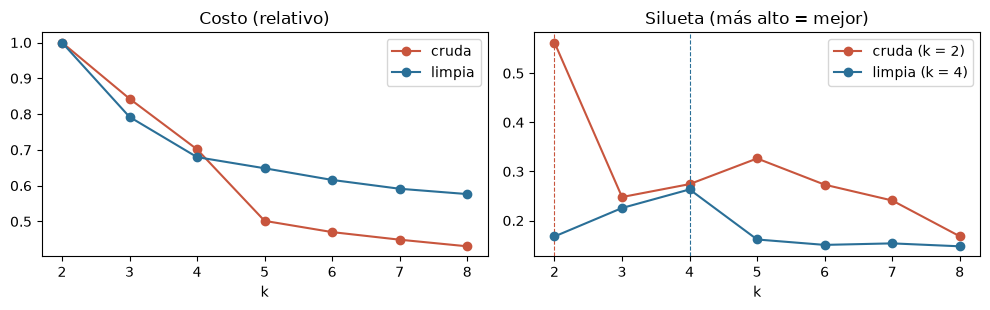

k elegido: {'cruda': 2, 'limpia': 4}


In [3]:
k_elegido = evaluacion.loc[evaluacion.groupby("escenario")["silueta"].idxmax()].set_index("escenario")["k"].to_dict()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for escenario, color in [("cruda", "#c8553d"), ("limpia", "#2a6f97")]:
    e = evaluacion[evaluacion.escenario == escenario]
    axes[0].plot(e.k, e.costo / e.costo.max(), "o-", color=color, label=escenario)
    axes[1].plot(e.k, e.silueta, "o-", color=color, label=f"{escenario} (k = {k_elegido[escenario]})")
    axes[1].axvline(k_elegido[escenario], color=color, ls="--", lw=0.8)
axes[0].set(title="Costo (relativo)", xlabel="k")
axes[1].set(title="Silueta (más alto = mejor)", xlabel="k")
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURAS / "kprototypes_eleccion_k.png", dpi=130)
plt.show()
print("k elegido:", k_elegido)

## 2. Entrenar con la muestra completa (50.000)

In [4]:
modelos_kp = {}
for escenario in ["cruda", "limpia"]:
    p = prep[escenario]
    modelos_kp[escenario] = entrenar_kprototypes(p["X_num"], p["X_cat"], k_elegido[escenario], n_init=3)
    print(escenario, "listo")

cruda listo


limpia listo


## 3. Distancia al prototipo y regla de atipicidad

Para cada contrato calculamos su distancia (fórmula del notebook 02) a todos los prototipos y nos quedamos con la menor: esa es la **distancia al centro de su cluster**.

**¿Cuándo es "demasiado lejos"?** Unos clusters son más dispersos que otros, así que no sirve un único umbral para todos. Para **cada cluster** usamos la regla de Tukey para valores extremos:

$$\text{límite}_c = Q3_c + 3 \times (Q3_c - Q1_c)$$

donde Q1 y Q3 son los cuartiles de las distancias **dentro del cluster c**. Un contrato es **atípico** si su distancia supera el límite de su cluster.

Para ordenar los atípicos de todos los clusters en una sola lista usamos el **puntaje = distancia / límite de su cluster** (puntaje > 1 → atípico).

In [ ]:
def distancia_a_prototipos(X_num, X_cat, modelo):
    centros = np.asarray(modelo.cluster_centroids_, dtype=float)
    centros_num, centros_cat = centros[:, :N_NUM], centros[:, N_NUM:]
    parte_numerica = ((X_num[:, None, :] - centros_num[None, :, :]) ** 2).sum(axis=2)
    parte_categorica = (X_cat[:, None, :] != centros_cat[None, :, :]).sum(axis=2)
    return parte_numerica + GAMMA * parte_categorica

def limites_por_cluster(cluster, distancia):
    tabla = pd.DataFrame({"cluster": cluster, "distancia": distancia})
    q = tabla.groupby("cluster")["distancia"].quantile([0.25, 0.75]).unstack()
    return q[0.75] + 3 * (q[0.75] - q[0.25])

resultados_kp = {}
limites = {}
for escenario in ["cruda", "limpia"]:
    p = prep[escenario]
    D = distancia_a_prototipos(p["X_num"], p["X_cat"], modelos_kp[escenario])
    cluster = D.argmin(axis=1)
    distancia = D.min(axis=1)
    limites[escenario] = limites_por_cluster(cluster, distancia)

    r = pd.DataFrame({"row_id": p["datos"]["row_id"], "kp_cluster": cluster, "kp_distancia": distancia})
    r["kp_puntaje"] = r["kp_distancia"] / r["kp_cluster"].map(limites[escenario])
    r["kp_atipico"] = r["kp_puntaje"] > 1
    resultados_kp[escenario] = r
    r.to_parquet(RESULTADOS / f"kprototypes_{escenario}.parquet")
    print(f"{escenario}: k = {k_elegido[escenario]}, atípicos = {r.kp_atipico.sum():,} ({100 * r.kp_atipico.mean():.2f}%)")

cruda: k = 2, atípicos = 2,405 (4.81%)
limpia: k = 4, atípicos = 1,504 (3.01%)


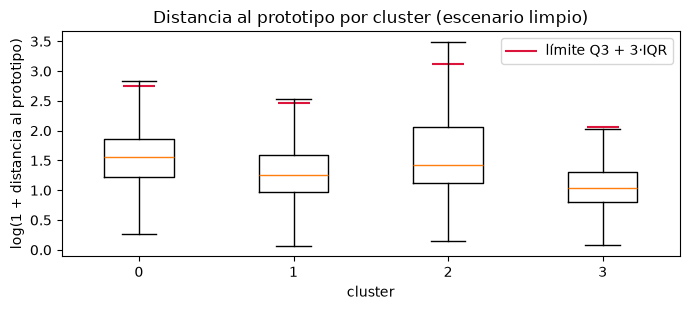

In [ ]:
r = resultados_kp["limpia"]
clusters = sorted(r.kp_cluster.unique())
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.boxplot([np.log1p(r.loc[r.kp_cluster == c, "kp_distancia"]) for c in clusters],
           tick_labels=[str(c) for c in clusters], showfliers=False)
ax.scatter(np.arange(1, len(clusters) + 1), np.log1p(limites["limpia"][clusters]),
           marker="_", s=500, color="crimson", label="límite Q3 + 3·IQR")
ax.set(xlabel="cluster", ylabel="log(1 + distancia al prototipo)",
       title="Distancia al prototipo por cluster (escenario limpio)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURAS / "kprototypes_distancias.png", dpi=130)
plt.show()

## 4. ¿Cómo es el "contrato típico" de cada cluster? (escenario limpio)

Volvemos los prototipos a sus unidades originales para interpretarlos.

In [7]:
p = prep["limpia"]
centros = np.asarray(modelos_kp["limpia"].cluster_centroids_, dtype=float)
num = pd.DataFrame(p["escalador"].inverse_transform(centros[:, :N_NUM]), columns=NUMERICAS)
cat = pd.DataFrame(p["codificador"].inverse_transform(centros[:, N_NUM:].astype(int)), columns=CATEGORICAS)

prototipos = pd.DataFrame({
    "valor contrato (millones COP)": (np.expm1(num["log_valor_contrato"]) / 1e6).round(1),
    "plazo (días)": np.expm1(num["log_plazo_dias"]).round(0),
    "adiciones / valor": num["ratio_adiciones"].round(2),
    "días firma→publicación": (np.sign(num["slog_dias_firma_cargue"]) * np.expm1(num["slog_dias_firma_cargue"].abs())).round(0),
})
prototipos = pd.concat([prototipos, cat[["modalidad_de_contratacion", "tipo_de_contrato", "orden_entidad",
                                         "tipo_identifi_del_contratista"]]], axis=1)
prototipos["% contratos"] = (resultados_kp["limpia"].kp_cluster.value_counts(normalize=True).sort_index() * 100).round(1)
prototipos["% atípicos"] = (resultados_kp["limpia"].groupby("kp_cluster").kp_atipico.mean() * 100).round(1)
prototipos.to_csv(TABLAS / "kprototypes_prototipos.csv", index_label="cluster")
prototipos

,valor contrato (millones COP),plazo (días),adiciones / valor,días firma→publicación,modalidad_de_contratacion,tipo_de_contrato,orden_entidad,tipo_identifi_del_contratista,% contratos,% atípicos
0,24.2,30.0,0.01,-8.0,CONTRATACION MINIMA CUANTIA,PRESTACION DE SERVICIOS,TERRITORIAL DISTRITAL MUNICIPAL NIVEL 6,NIT DE PERSONA JURIDICA,13.0,2.5
1,2.0,18.0,0.00,14.0,REGIMEN ESPECIAL,PRESTACION DE SERVICIOS,TERRITORIAL DEPARTAMENTAL DESCENTRALIZADO,CEDULA DE CIUDADANIA,28.6,1.2
2,17.7,130.0,0.40,4.0,CONTRATACION DIRECTA (LEY 1150 DE 2007),PRESTACION DE SERVICIOS,TERRITORIAL DEPARTAMENTAL DESCENTRALIZADO,CEDULA DE CIUDADANIA,7.6,5.2
3,12.9,134.0,0.00,11.0,CONTRATACION DIRECTA (LEY 1150 DE 2007),PRESTACION DE SERVICIOS,TERRITORIAL DISTRITAL MUNICIPAL NIVEL 6,CEDULA DE CIUDADANIA,50.8,3.8


In [ ]:
centros = np.asarray(modelos_kp["limpia"].cluster_centroids_, dtype=float)
joblib.dump({
    "centros_num": centros[:, :N_NUM],
    "centros_cat": centros[:, N_NUM:],
    "limites": limites["limpia"].to_numpy(),
    "gamma": GAMMA,
}, MODELOS / "kprototypes_limpio.joblib")
print("Guardado")

Guardado
